## Interval Analysis

In [1]:
# !pip install tensorboardX

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
# from tensorboardX import SummaryWriter

use_cuda = False
device = torch.device("cuda" if use_cuda else "cpu")
batch_size = 64

np.random.seed(42)
torch.manual_seed(42)


## Dataloaders
train_dataset = datasets.MNIST('mnist_data/', train=True, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## Simple NN. You can change this if you want. If you change it, mention the architectural details in your report.
#3 hidden layers, with 50 neurons each.
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc = nn.Linear(28*28, 50)
        self.fc2 = nn.Linear(50, 50)
        self.fc3 = nn.Linear(50, 50)
        self.fc4 = nn.Linear(50, 10)

    def forward(self, x):
        x = x.view((-1, 28*28))
        x = F.relu(self.fc(x))
        x = F.relu(self.fc2(x))
        x = F.relu(self.fc3(x))
        x = self.fc4(x)
        return x

class Normalize(nn.Module):
    def forward(self, x):
        return (x - 0.1307)/0.3081

# Add the data normalization as a first "layer" to the network
# this allows us to search for adverserial examples to the real image, rather than
# to the normalized image
model = nn.Sequential(Normalize(), Net())

model = model.to(device)
model.train()


Sequential(
  (0): Normalize()
  (1): Net(
    (fc): Linear(in_features=784, out_features=50, bias=True)
    (fc2): Linear(in_features=50, out_features=50, bias=True)
    (fc3): Linear(in_features=50, out_features=50, bias=True)
    (fc4): Linear(in_features=50, out_features=10, bias=True)
  )
)

In [2]:
def train_model(model, num_epochs):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

    start_time = time.time()

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader):.3f}')

    training_time = time.time() - start_time
    return training_time

def ibp_bounds(model, images, epsilon):
    net = model[1]  # Extract the Net part of the model

    lower = torch.clamp(images - epsilon, 0, 1)
    upper = torch.clamp(images + epsilon, 0, 1)

    lower = (lower - 0.1307) / 0.3081
    upper = (upper - 0.1307) / 0.3081

    lower = lower.view(images.size(0), -1)
    upper = upper.view(images.size(0), -1)

    layers = [net.fc, net.fc2, net.fc3, net.fc4]

    for i, layer in enumerate(layers):
        w_pos = torch.clamp(layer.weight, min=0)
        w_neg = torch.clamp(layer.weight, max=0)

        lower_new = F.linear(lower, w_pos) + F.linear(upper, w_neg) + layer.bias
        upper_new = F.linear(upper, w_pos) + F.linear(lower, w_neg) + layer.bias

        lower, upper = lower_new, upper_new

        if i < 3:  # Apply ReLU for the first three layers
            lower = F.relu(lower)
            upper = F.relu(upper)

    return lower, upper

def train_ibp(model, num_epochs):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

    start_time = time.time()

    for epoch in range(num_epochs):
        kappa = 1.0 - (0.5 * epoch / max(num_epochs - 1, 1))  # Linearly decrease kappa from 1 to 0.5
        epsilon_train = 0.1 * epoch / max(num_epochs - 1, 1)  # Linearly increase epsilon from 0 to 0.1

        model.train()
        running_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)

            # Compute IBP bounds
            lower, upper = ibp_bounds(model, images, epsilon_train)

            true_lower = lower.gather(1, labels.unsqueeze(1))
            robust_logits = upper - true_lower
            robust_logits = robust_logits.scatter(1, labels.unsqueeze(1), 0)  # Set the true class logit to 0
            loss_robust = criterion(robust_logits, labels)
            loss = kappa * loss + (1 - kappa) * loss_robust
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f'IBP Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader):.3f}, Epsilon: {epsilon_train:.3f}, Kappa: {kappa:.3f}')

    training_time = time.time() - start_time
    return training_time

def test_model(model):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            predicted = torch.argmax(outputs, dim=1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    accuracy = 100 * correct / total
    print(f'Accuracy on test images: {accuracy:.2f}%')
    return accuracy

In [3]:
num_epochs = 15

# Standard Training

print("Starting standard training...")
model = nn.Sequential(Normalize(), Net()).to(device)  # Reinitialize the model for standard training
standard_training_time = train_model(model, num_epochs)
print("\nStandard training results:")
standard_accuracy = test_model(model)
print(f"Standard training time: {standard_training_time:.2f} seconds")

# IBP Training

print("\nStarting IBP training...")
model_ibp = nn.Sequential(Normalize(), Net()).to(device)  # Reinitialize the model for IBP training
ibp_training_time = train_ibp(model_ibp, num_epochs)
print("\nIBP training results:")
ibp_accuracy = test_model(model_ibp)
print(f"IBP training time: {ibp_training_time:.2f} seconds")

# Summary of results
print(f"standard_accuracy: {standard_accuracy:.2f}%, standard_training_time: {standard_training_time:.2f} seconds")
print(f"ibp_accuracy: {ibp_accuracy:.2f}%, ibp_training_time: {ibp_training_time:.2f} seconds")


Starting standard training...
Epoch 1/15, Loss: 1.265
Epoch 2/15, Loss: 0.365
Epoch 3/15, Loss: 0.288
Epoch 4/15, Loss: 0.241
Epoch 5/15, Loss: 0.207
Epoch 6/15, Loss: 0.180
Epoch 7/15, Loss: 0.160
Epoch 8/15, Loss: 0.144
Epoch 9/15, Loss: 0.132
Epoch 10/15, Loss: 0.121
Epoch 11/15, Loss: 0.112
Epoch 12/15, Loss: 0.103
Epoch 13/15, Loss: 0.096
Epoch 14/15, Loss: 0.091
Epoch 15/15, Loss: 0.085

Standard training results:
Accuracy on test images: 96.72%
Standard training time: 82.86 seconds

Starting IBP training...
IBP Epoch 1/15, Loss: 1.427, Epsilon: 0.000, Kappa: 1.000
IBP Epoch 2/15, Loss: 0.615, Epsilon: 0.007, Kappa: 0.964
IBP Epoch 3/15, Loss: 0.604, Epsilon: 0.014, Kappa: 0.929
IBP Epoch 4/15, Loss: 0.582, Epsilon: 0.021, Kappa: 0.893
IBP Epoch 5/15, Loss: 0.577, Epsilon: 0.029, Kappa: 0.857
IBP Epoch 6/15, Loss: 0.583, Epsilon: 0.036, Kappa: 0.821
IBP Epoch 7/15, Loss: 0.599, Epsilon: 0.043, Kappa: 0.786
IBP Epoch 8/15, Loss: 0.625, Epsilon: 0.050, Kappa: 0.750
IBP Epoch 9/15, 

In [4]:
def pgd_attack(model, images, labels, epsilon=0.1, alpha=0.01, iterations=40):
    model.eval()

    original_images = images.detach().clone()

    adv_images = original_images + torch.empty_like(original_images).uniform_(-epsilon, epsilon)
    adv_images = torch.clamp(adv_images, 0, 1).detach()

    for _ in range(iterations):
        adv_images = adv_images.detach().requires_grad_(True)
        outputs = model(adv_images)
        loss = F.cross_entropy(outputs, labels)
        grad = torch.autograd.grad(loss, adv_images)[0]

        with torch.no_grad():
            adv_images = adv_images + alpha * grad.sign()
            delta = torch.clamp(adv_images - original_images, min=-epsilon, max=epsilon)
            adv_images = torch.clamp(original_images + delta, 0, 1)
    return adv_images.detach()

def pgd_test(model, epsilon=0.1, alpha=0.01, iterations=40):
    model.eval()
    correct = 0
    total = 0
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        adv_images = pgd_attack(model, images, labels, epsilon, alpha, iterations)
        with torch.no_grad():
            outputs = model(adv_images)
            predicted = torch.argmax(outputs, dim=1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    accuracy = 100 * correct / total
    return accuracy

# Evaluate the model on adversarial examples

print("\nEvaluating the model on adversarial examples...")

standard_adv_accuracy = pgd_test(model, epsilon=0.1, alpha=0.01, iterations=40)
print(f"Standard model accuracy on adversarial examples: {standard_adv_accuracy:.2f}%")

# Evaluate the IBP-trained model on adversarial examples
print("\nEvaluating the IBP-trained model on adversarial examples...")
ibp_adv_accuracy = pgd_test(model_ibp, epsilon=0.1, alpha=0.01, iterations=40)
print(f"IBP-trained model accuracy on adversarial examples: {ibp_adv_accuracy:.2f}%")


Evaluating the model on adversarial examples...
Standard model accuracy on adversarial examples: 5.89%

Evaluating the IBP-trained model on adversarial examples...
IBP-trained model accuracy on adversarial examples: 72.12%


In [5]:
train_model(model, 15)
test_model(model)

Epoch 1/15, Loss: 0.081
Epoch 2/15, Loss: 0.076
Epoch 3/15, Loss: 0.072
Epoch 4/15, Loss: 0.068
Epoch 5/15, Loss: 0.065
Epoch 6/15, Loss: 0.061
Epoch 7/15, Loss: 0.058
Epoch 8/15, Loss: 0.056
Epoch 9/15, Loss: 0.053
Epoch 10/15, Loss: 0.050
Epoch 11/15, Loss: 0.048
Epoch 12/15, Loss: 0.046
Epoch 13/15, Loss: 0.044
Epoch 14/15, Loss: 0.041
Epoch 15/15, Loss: 0.039
Accuracy on test images: 97.32%


97.32

### Write the interval analysis for the simple model

In [6]:
## TODO: Write the interval analysis for the simple model
## you can use https://github.com/Zinoex/bound_propagation

# finidng the lower and upper bounds through all 3 hidden layers given the input image and epsilon

def interval_bounds(model, input_image, epsilon):
    net = model[1]

    # Get the lower and upper bounds of the input image
    lower_bound = torch.clamp(input_image - epsilon, 0, 1)
    upper_bound = torch.clamp(input_image + epsilon, 0, 1)

    lower_bound = (lower_bound - 0.1307) / 0.3081
    upper_bound = (upper_bound - 0.1307) / 0.3081

    lower_bound = lower_bound.view(input_image.size(0), -1)
    upper_bound = upper_bound.view(input_image.size(0), -1)

    # Propagate the bounds for the 3 hidden layers
    layers = [net.fc, net.fc2, net.fc3]

    for layer in layers:
        w_pos = torch.clamp(layer.weight, min=0)
        w_neg = torch.clamp(layer.weight, max=0)

        lower_bound_new = F.linear(lower_bound, w_pos) + F.linear(upper_bound, w_neg) + layer.bias
        upper_bound_new = F.linear(upper_bound, w_pos) + F.linear(lower_bound, w_neg) + layer.bias

        lower_bound, upper_bound = lower_bound_new, upper_bound_new

        # Apply ReLU activation for the hidden layers
        lower_bound = F.relu(lower_bound_new)
        upper_bound = F.relu(upper_bound_new)

    return lower_bound, upper_bound
# Verify the model's robustness for a given epsilon

def verify (model, images, Labels, epsilon):
    net = model[1]
    z1_lower, z1_upper = interval_bounds(model, images, epsilon)

    # Get the weights and biases of the final output layer
    W4 = net.fc4.weight
    b4 = net.fc4.bias

    W4_y = W4[Labels]
    b4_y = b4[Labels]

    diff_W4 = W4_y.unsqueeze(1) - W4.unsqueeze(0)
    diff_b4 = b4_y.unsqueeze(1) - b4.unsqueeze(0)

    diff_W4_pos = torch.clamp(diff_W4, min=0)
    diff_W4_neg = torch.clamp(diff_W4, max=0)

    lower_diff = (torch.sum(diff_W4_pos * z1_lower.unsqueeze(1) + diff_W4_neg * z1_upper.unsqueeze(1), dim=2) + diff_b4)

    verified = (lower_diff >= -1e-7).all(dim=1)

    return verified

# Evaluate the model's clean and verified accuracy for a given epsilon

def evaluate_verification(model, test_loader, epsilon):
    model.eval()
    clean_count = 0
    verified_count = 0
    total_count = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            predictions = torch.argmax(outputs, dim=1)

            clean_count += (predictions == labels).sum().item()
            total_count += labels.size(0)

            verified = verify(model, images, labels, epsilon)
            verified_count += (verified & (predictions == labels)).sum().item()

    clean_accuracy = 100 * clean_count / total_count
    verified_accuracy = 100 * verified_count / total_count

    return clean_accuracy, verified_accuracy

In [7]:
# trying to find the best epsilon for which the model is still robust. 
# We will evaluate the model for different values of epsilon and report the clean accuracy, verified accuracy, and time taken for each evaluation.

epsilon = np.linspace(0.01, 0.1, 10)

results = []

model_ibp.eval()

for eps in epsilon:
    start_time = time.time()
    clean_acc, verified_acc = evaluate_verification(model_ibp, test_loader, float(eps))
    elapsed_time = time.time() - start_time
    results.append((eps, clean_acc, verified_acc, elapsed_time))
    print(f"Epsilon: {eps:.3f}, Clean Accuracy: {clean_acc:.2f}%, Verified Accuracy: {verified_acc:.2f}%, Time: {elapsed_time:.2f}s")

Epsilon: 0.010, Clean Accuracy: 90.76%, Verified Accuracy: 89.07%, Time: 0.90s
Epsilon: 0.020, Clean Accuracy: 90.76%, Verified Accuracy: 87.38%, Time: 0.84s
Epsilon: 0.030, Clean Accuracy: 90.76%, Verified Accuracy: 85.43%, Time: 0.85s
Epsilon: 0.040, Clean Accuracy: 90.76%, Verified Accuracy: 83.40%, Time: 0.85s
Epsilon: 0.050, Clean Accuracy: 90.76%, Verified Accuracy: 81.26%, Time: 0.88s
Epsilon: 0.060, Clean Accuracy: 90.76%, Verified Accuracy: 78.64%, Time: 1.07s
Epsilon: 0.070, Clean Accuracy: 90.76%, Verified Accuracy: 75.64%, Time: 1.22s
Epsilon: 0.080, Clean Accuracy: 90.76%, Verified Accuracy: 72.32%, Time: 1.25s
Epsilon: 0.090, Clean Accuracy: 90.76%, Verified Accuracy: 68.43%, Time: 0.87s
Epsilon: 0.100, Clean Accuracy: 90.76%, Verified Accuracy: 64.09%, Time: 0.92s



Finding adversarial examples among uncertified images...

Adversarial examples found:


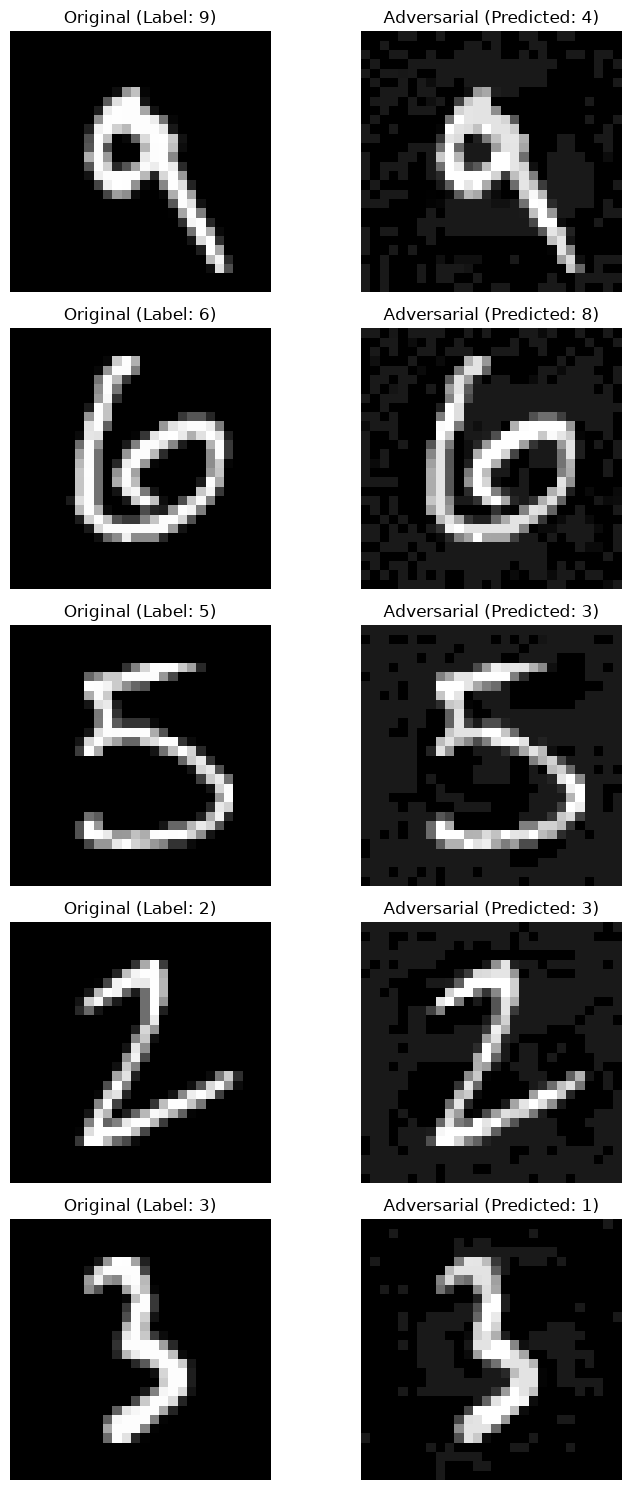

In [8]:
# find the adversarial examples among images that are not certified

epsilon = 0.1
adversarial_examples = []
original_examples = []
true_labels = []
predicted_labels = []

model_ibp.eval()

print("\nFinding adversarial examples among uncertified images...")

for images, labels in test_loader:
    images, labels = images.to(device), labels.to(device)

    with torch.no_grad():
        outputs = model_ibp(images)
        predictions = torch.argmax(outputs, dim=1)

        clean_correct = (predictions == labels)
        certified = verify(model_ibp, images, labels, epsilon)
        candidates = clean_correct & ~certified

    if candidates.sum().item() == 0:
        continue

    candidate_images = images[candidates]
    candidate_labels = labels[candidates]

    adv_images = pgd_attack(model_ibp, candidate_images, candidate_labels, epsilon=epsilon, alpha=0.01, iterations=40)

    with torch.no_grad():
        adv_outputs = model_ibp(adv_images)
        adv_predictions = torch.argmax(adv_outputs, dim=1)

        successful_adv = (adv_predictions != candidate_labels)

    for i in range(len(candidate_labels)):
        if successful_adv[i]:
            adversarial_examples.append(adv_images[i].cpu())
            original_examples.append(candidate_images[i].cpu())
            true_labels.append(candidate_labels[i].item())
            predicted_labels.append(adv_predictions[i].item())
        if len(adversarial_examples) >= 5:
            break
    if len(adversarial_examples) >= 5:
        break

if len(adversarial_examples) > 0:
    print("\nAdversarial examples found:")
    fig, axes = plt.subplots(len(adversarial_examples), 2, figsize=(8, 3 * len(adversarial_examples)))
    if len(adversarial_examples) == 1:
        axes = np.array([axes])  # Ensure axes is 2D for consistent indexing
    for i in range(len(adversarial_examples)):
        original_image = original_examples[i].squeeze().numpy()
        adversarial_image = adversarial_examples[i].squeeze().numpy()

        axes[i, 0].imshow(original_image, cmap='gray')
        axes[i, 0].set_title(f"Original (Label: {true_labels[i]})")
        axes[i, 1].imshow(adversarial_image, cmap='gray')
        axes[i, 1].set_title(f"Adversarial (Predicted: {predicted_labels[i]})")
        axes[i, 0].axis('off')
        axes[i, 1].axis('off')
    plt.tight_layout()
    plt.show()
else:
    print("No adversarial examples found.")

,Epsilon,Clean Accuracy,Verified Accuracy,Time
0,0.01,90.76,89.07,0.8958
1,0.02,90.76,87.38,0.8428
2,0.03,90.76,85.43,0.8498
3,0.04,90.76,83.40,0.8535
4,0.05,90.76,81.26,0.8780
5,0.06,90.76,78.64,1.0726
6,0.07,90.76,75.64,1.2164
7,0.08,90.76,72.32,1.2490
8,0.09,90.76,68.43,0.8702
9,0.10,90.76,64.09,0.9222


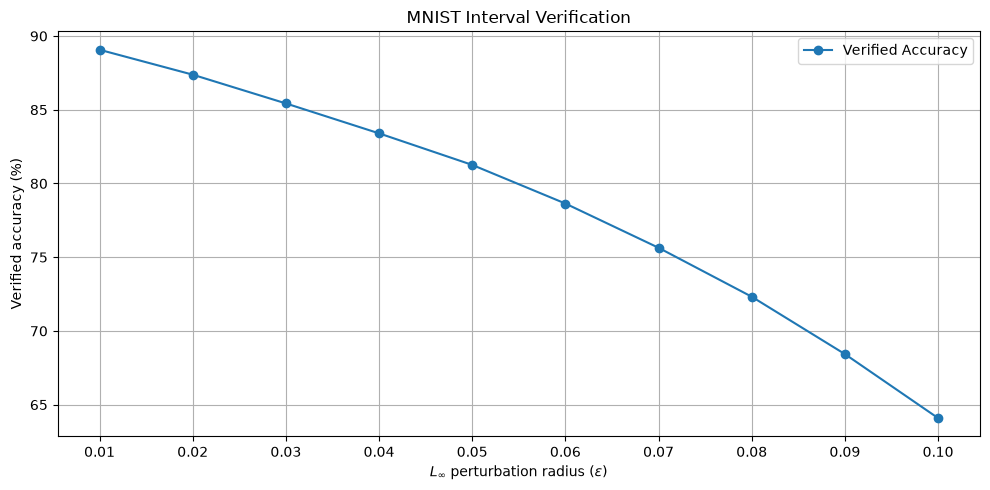

In [10]:
import pandas as pd

# Creating a DataFrame to display the results

results_df = pd.DataFrame(results, columns=['Epsilon', 'Clean Accuracy', 'Verified Accuracy', 'Time'])

display(results_df.round(4))

plt.figure(figsize=(10, 5))
plt.plot(results_df['Epsilon'], results_df['Verified Accuracy'], label='Verified Accuracy', marker='o')
plt.xlabel(r"$L_\infty$ perturbation radius ($\epsilon$)")
plt.ylabel("Verified accuracy (%)")
plt.title("MNIST Interval Verification")
plt.xticks(results_df['Epsilon'].round(2))
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()